# 03 - Signatures
Score the three developmental modules, read module geography and the pseudotime gradient, and settle Gate 2 (module pattern) / Gate 3 (NA - non-branching). Deliverable signature UMAPs show RAW per-cell scores.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 3920 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present


In [ ]:
# GATE 2: does the embryonic module pattern appear? (module geography + terminal Crest)
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\\ngradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'\\nGast-high decile mean pseudotime = {tn[(adata.obs.Gast_sm>=adata.obs.Gast_sm.quantile(.9)).values].mean():.2f} (root end)')
print(f'pSom-high decile mean pseudotime = {tn[(adata.obs.pSom_sm>=adata.obs.pSom_sm.quantile(.9)).values].mean():.2f} (terminal end)')
print(f'Crest-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
# which arm does Crest lean toward? Gast-side (early) vs pSom-side (late)
crest_gast_r = np.corrcoef(adata.obs.Crest_sm, adata.obs.Gast_sm)[0,1]
crest_psom_r = np.corrcoef(adata.obs.Crest_sm, adata.obs.pSom_sm)[0,1]
arm = 'pSom' if crest_psom_r > crest_gast_r else 'Gast'
print(f'\\nCrest leans toward the {arm} side (Crest-pSom r={crest_psom_r:+.2f} vs Crest-Gast r={crest_gast_r:+.2f})')
print('GATE 2 = GO (non-branching): one continuous Gast(early)<->pSom(late) cross-repression axis,')
print('  organized module geography with a Crest gradient; no co-expression hub -> collapsed bifurcation.')
print('GATE 3 = NA (no bifurcation to test for hub cross-repression).')
print('Crest-arm FLAG: %s (flag only if Crest enriches the Gast arm)' % ('none - Crest on pSom side' if arm=='pSom' else 'FLAG - Crest on Gast arm'))

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.53
  Crest_sm vs Gast_sm: r = -0.51
  Crest_sm vs pSom_sm: r = -0.36
\ngradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.583
  pSom_sm: rho = +0.741
  Crest_sm: rho = +0.022
\nGast-high decile mean pseudotime = 0.16 (root end)
pSom-high decile mean pseudotime = 0.99 (terminal end)
Crest-high decile mean pseudotime = 0.56
\nCrest leans toward the pSom side (Crest-pSom r=-0.36 vs Crest-Gast r=-0.51)
GATE 2 = GO (non-branching): one continuous Gast(early)<->pSom(late) cross-repression axis,
  organized module geography with a Crest gradient; no co-expression hub -> collapsed bifurcation.
GATE 3 = NA (no bifurcation to test for hub cross-repression).
Crest-arm FLAG: none - Crest on pSom side (flag only if Crest enriches the Gast arm)


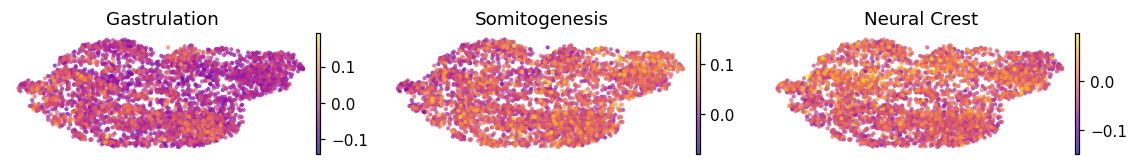

In [ ]:
# module maps in the house linear layout (pseudotime left -> right); RAW scores shown (deliverable rule)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout()
fig

<string>:18: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<string>:18: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<string>:18: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


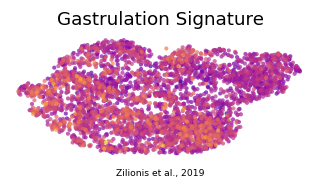

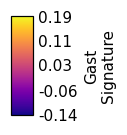

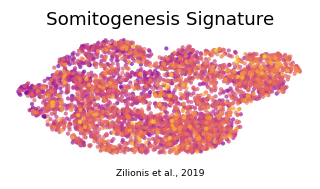

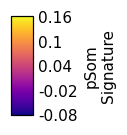

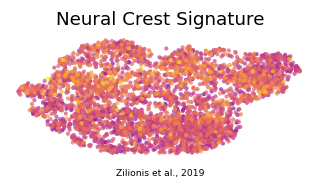

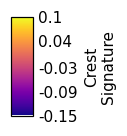

In [ ]:
# DELIVERABLE signature UMAPs (raw scores) + colorbars, one per module, house (3.5,1.5) aspect
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
figs=[]
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')
    figs.append(fig)
figs[0]

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (3920, 28282)
